# NYC Taxi Demand — Data Preparation

This notebook prepares NYC Yellow Taxi trip data from 2024 for daily
demand forecasting. Data processing uses Polars and lazy execution
to limit memory usage.

The final dataset contains one row per day, with the number of trips
as the target variable and aggregated trip features.

In [1]:
from pathlib import Path
from datetime import datetime

import polars as pl
import matplotlib.pyplot as plt

DATA_DIR = Path("../labs/data")
OUTPUT_PATH = Path("dataset.parquet")

trip_paths = [DATA_DIR / f"{month}.parquet" for month in range(7, 13)]
zones_path = DATA_DIR / "taxi_zone_lookup.csv"

missing_files = [path for path in [*trip_paths, zones_path] if not path.is_file()]

if missing_files:
    raise FileNotFoundError(f"Missing input files: {missing_files}")

print(f"Polars version: {pl.__version__}")
print(f"Monthly files found: {len(trip_paths)}")
print(f"Taxi zone lookup found: {zones_path.is_file()}")

Polars version: 1.24.0
Monthly files found: 6
Taxi zone lookup found: True


## 1. Data loading

Due to limited RAM and a previous out-of-memory failure, this notebook
uses the latest six months of 2024: July–December.

Monthly files are scanned lazily, and timestamp units are normalized
to milliseconds before concatenation. Only trips starting within
this period and ending no later than January 1, 2025 at midnight
are included.

In [2]:
monthly_frames = [
    pl.scan_parquet(path).with_columns(
        pl.col("tpep_pickup_datetime").dt.cast_time_unit("ms"),
        pl.col("tpep_dropoff_datetime").dt.cast_time_unit("ms"),
    )
    for path in trip_paths
]

trips_raw = pl.concat(monthly_frames)

trips_2024 = trips_raw.filter(
    pl.col("tpep_pickup_datetime") >= datetime(2024, 7, 1),
    pl.col("tpep_pickup_datetime") < datetime(2025, 1, 1),
    pl.col("tpep_dropoff_datetime") <= datetime(2025, 1, 1),
)

taxi_zones = pl.read_csv(zones_path)

print("Trips object type:", type(trips_2024))
print("Taxi zones:", taxi_zones.shape)
print(trips_2024.collect_schema())

Trips object type: <class 'polars.lazyframe.frame.LazyFrame'>
Taxi zones: (265, 4)
Schema([('VendorID', Int32), ('tpep_pickup_datetime', Datetime(time_unit='ms', time_zone=None)), ('tpep_dropoff_datetime', Datetime(time_unit='ms', time_zone=None)), ('passenger_count', Int64), ('trip_distance', Float64), ('RatecodeID', Int64), ('store_and_fwd_flag', String), ('PULocationID', Int32), ('DOLocationID', Int32), ('payment_type', Int64), ('fare_amount', Float64), ('extra', Float64), ('mta_tax', Float64), ('tip_amount', Float64), ('tolls_amount', Float64), ('improvement_surcharge', Float64), ('total_amount', Float64), ('congestion_surcharge', Float64), ('Airport_fee', Float64)])


## 2. Data cleaning

Missing passenger counts are replaced with 1. Trips with zero passengers
are removed, and counts above 6 are capped at 6.

Trips must have a non-negative duration of at most two hours.
Financial values are converted to absolute values, and trips with
any financial value above USD 1,000 are removed.
Missing financial values are preserved.

In [3]:
money_columns = [
    "fare_amount",
    "extra",
    "mta_tax",
    "tip_amount",
    "tolls_amount",
    "improvement_surcharge",
    "total_amount",
    "congestion_surcharge",
    "Airport_fee",
]

trip_duration = pl.col("tpep_dropoff_datetime") - pl.col("tpep_pickup_datetime")

trips_clean = (
    trips_2024.with_columns(
        pl.col("passenger_count")
        .fill_null(1)
        .clip(upper_bound=6)
        .alias("passenger_count")
    )
    .filter(pl.col("passenger_count") > 0)
    .filter(
        trip_duration >= pl.duration(seconds=0),
        trip_duration <= pl.duration(hours=2),
    )
    .with_columns(pl.col(money_columns).abs())
    .filter(
        ~pl.any_horizontal(
            [(pl.col(column) > 1000).fill_null(False) for column in money_columns]
        )
    )
    .with_columns(pl.col("passenger_count").cast(pl.UInt8))
)

print("Cleaning pipeline created.")
print("Object type:", type(trips_clean))

Cleaning pipeline created.
Object type: <class 'polars.lazyframe.frame.LazyFrame'>


### Provider and rate code validation

Rows with missing or unrecognized provider and rate codes are removed.
Rate code 99 is also excluded because it represents an unknown rate.

Small integer types are used for passenger counts, codes, and location
identifiers to reduce memory usage.

In [4]:
valid_vendor_ids = [1, 2, 6, 7]
valid_ratecode_ids = [1, 2, 3, 4, 5, 6]

trips_clean = trips_clean.filter(
    pl.col("VendorID").is_in(valid_vendor_ids),
    pl.col("RatecodeID").is_in(valid_ratecode_ids),
).with_columns(
    pl.col("VendorID").cast(pl.UInt8),
    pl.col("RatecodeID").cast(pl.UInt8),
    pl.col("payment_type").cast(pl.UInt8),
    pl.col("PULocationID").cast(pl.UInt16),
    pl.col("DOLocationID").cast(pl.UInt16),
)

print(trips_clean.collect_schema())

Schema([('VendorID', UInt8), ('tpep_pickup_datetime', Datetime(time_unit='ms', time_zone=None)), ('tpep_dropoff_datetime', Datetime(time_unit='ms', time_zone=None)), ('passenger_count', UInt8), ('trip_distance', Float64), ('RatecodeID', UInt8), ('store_and_fwd_flag', String), ('PULocationID', UInt16), ('DOLocationID', UInt16), ('payment_type', UInt8), ('fare_amount', Float64), ('extra', Float64), ('mta_tax', Float64), ('tip_amount', Float64), ('tolls_amount', Float64), ('improvement_surcharge', Float64), ('total_amount', Float64), ('congestion_surcharge', Float64), ('Airport_fee', Float64)])


## 3. Data transformation

Payment methods are grouped into credit card, cash, and other.
All remaining payment codes, including missing values, are assigned
to the other category.

Pickup and dropoff boroughs are obtained from the taxi zone lookup.
Unmatched boroughs are labeled Unknown.

Airport rides have a non-zero airport fee. Rush-hour rides start
on weekdays between 06:30–09:30 or 15:30–20:00, including endpoints.

In [5]:
pickup_zones = taxi_zones.select(
    pl.col("LocationID").cast(pl.UInt16).alias("PULocationID"),
    pl.col("Borough").fill_null("Unknown").alias("pickup_borough"),
).lazy()

dropoff_zones = taxi_zones.select(
    pl.col("LocationID").cast(pl.UInt16).alias("DOLocationID"),
    pl.col("Borough").fill_null("Unknown").alias("dropoff_borough"),
).lazy()

pickup_time = pl.col("tpep_pickup_datetime").dt.time()

is_weekday = pl.col("tpep_pickup_datetime").dt.weekday() <= 5

is_rush_time = pickup_time.is_between(
    pl.time(6, 30), pl.time(9, 30), closed="both"
) | pickup_time.is_between(pl.time(15, 30), pl.time(20, 0), closed="both")

trips_transformed = (
    trips_clean.join(
        pickup_zones,
        on="PULocationID",
        how="left",
        validate="m:1",
    )
    .join(
        dropoff_zones,
        on="DOLocationID",
        how="left",
        validate="m:1",
    )
    .with_columns(
        pl.when(pl.col("payment_type") == 1)
        .then(pl.lit("credit_card"))
        .when(pl.col("payment_type") == 2)
        .then(pl.lit("cash"))
        .otherwise(pl.lit("other"))
        .cast(pl.Categorical)
        .alias("payment_method"),
        pl.col("pickup_borough").fill_null("Unknown").cast(pl.Categorical),
        pl.col("dropoff_borough").fill_null("Unknown").cast(pl.Categorical),
        (pl.col("Airport_fee").fill_null(0) != 0).alias("is_airport_ride"),
        (is_weekday & is_rush_time).alias("is_rush_hour"),
        pl.col("tpep_pickup_datetime").dt.date().alias("date"),
    )
    .drop(
        "PULocationID",
        "DOLocationID",
        "payment_type",
    )
)

print(trips_transformed.collect_schema())

Schema([('VendorID', Int32), ('tpep_pickup_datetime', Datetime(time_unit='ms', time_zone=None)), ('tpep_dropoff_datetime', Datetime(time_unit='ms', time_zone=None)), ('passenger_count', UInt8), ('trip_distance', Float64), ('RatecodeID', Int64), ('store_and_fwd_flag', String), ('fare_amount', Float64), ('extra', Float64), ('mta_tax', Float64), ('tip_amount', Float64), ('tolls_amount', Float64), ('improvement_surcharge', Float64), ('total_amount', Float64), ('congestion_surcharge', Float64), ('Airport_fee', Float64), ('pickup_borough', Categorical(ordering='physical')), ('dropoff_borough', Categorical(ordering='physical')), ('payment_method', Categorical(ordering='physical')), ('is_airport_ride', Boolean), ('is_rush_hour', Boolean), ('date', Date)])


## 4. Daily feature extraction

Payment methods and pickup/dropoff boroughs are dummy encoded.
Their indicators are summed directly during daily aggregation,
avoiding materialization of a large encoded trip table.

Daily features include trip counts, financial aggregates, passenger
counts, and calendar information.

In [6]:
boroughs = sorted(set(taxi_zones["Borough"].drop_nulls().to_list()) | {"Unknown"})

payment_methods = ["credit_card", "cash", "other"]


def feature_name(value):
    return value.lower().replace(" ", "_").replace("/", "_").replace("-", "_")


dummy_aggregations = [
    (pl.col("payment_method") == method)
    .cast(pl.UInt32)
    .sum()
    .alias(f"payment_{method}_count")
    for method in payment_methods
]

for column, prefix in [
    ("pickup_borough", "pickup"),
    ("dropoff_borough", "dropoff"),
]:
    dummy_aggregations.extend(
        [
            (pl.col(column) == borough)
            .cast(pl.UInt32)
            .sum()
            .alias(f"{prefix}_{feature_name(borough)}_count")
            for borough in boroughs
        ]
    )

payment_amount_aggregations = [
    pl.col("total_amount")
    .filter(pl.col("payment_method") == method)
    .sum()
    .alias(f"total_amount_{method}")
    for method in payment_methods
]

daily_features = (
    trips_transformed.group_by("date")
    .agg(
        pl.len().alias("trip_count"),
        pl.col("is_airport_ride").cast(pl.UInt32).sum().alias("airport_trip_count"),
        pl.col("is_rush_hour").cast(pl.UInt32).sum().alias("rush_hour_trip_count"),
        pl.col("fare_amount").mean().alias("average_fare_amount"),
        pl.col("trip_distance").median().alias("median_trip_distance"),
        pl.col("total_amount").sum().alias("total_amount"),
        pl.col("congestion_surcharge").sum().alias("total_congestion_surcharge"),
        pl.col("passenger_count").cast(pl.UInt32).sum().alias("total_passengers"),
        *dummy_aggregations,
        *payment_amount_aggregations,
    )
    .with_columns(
        pl.col("date").dt.quarter().cast(pl.UInt8).alias("quarter"),
        pl.col("date").dt.month().cast(pl.UInt8).alias("month"),
        pl.col("date").dt.day().cast(pl.UInt8).alias("day_of_month"),
        pl.col("date").dt.weekday().cast(pl.UInt8).alias("day_of_week"),
        (pl.col("date").dt.weekday() >= 6).alias("is_weekend"),
    )
    .sort("date")
)

print(daily_features.collect_schema())

Schema([('date', Date), ('trip_count', UInt32), ('airport_trip_count', UInt32), ('rush_hour_trip_count', UInt32), ('average_fare_amount', Float64), ('median_trip_distance', Float64), ('total_amount', Float64), ('total_congestion_surcharge', Float64), ('total_passengers', UInt32), ('payment_credit_card_count', UInt32), ('payment_cash_count', UInt32), ('payment_other_count', UInt32), ('pickup_bronx_count', UInt32), ('pickup_brooklyn_count', UInt32), ('pickup_ewr_count', UInt32), ('pickup_manhattan_count', UInt32), ('pickup_n_a_count', UInt32), ('pickup_queens_count', UInt32), ('pickup_staten_island_count', UInt32), ('pickup_unknown_count', UInt32), ('dropoff_bronx_count', UInt32), ('dropoff_brooklyn_count', UInt32), ('dropoff_ewr_count', UInt32), ('dropoff_manhattan_count', UInt32), ('dropoff_n_a_count', UInt32), ('dropoff_queens_count', UInt32), ('dropoff_staten_island_count', UInt32), ('dropoff_unknown_count', UInt32), ('total_amount_credit_card', Float64), ('total_amount_cash', Float6

In [7]:
from time import perf_counter

start = perf_counter()

july_features = daily_features.filter(
    pl.col("date") >= datetime(2024, 7, 1).date(),
    pl.col("date") < datetime(2024, 8, 1).date(),
).collect(streaming=True)

print(f"Execution time: {perf_counter() - start:.2f} seconds")
print("Shape:", july_features.shape)

july_features.head()

/tmp/ipykernel_1298/2699558370.py:11: DeprecationWarning: The old streaming engine is being deprecated and will soon be replaced by the new streaming engine. Starting Polars version 1.23.0 and until the new streaming engine is released, the old streaming engine may become less usable. For people who rely on the old streaming engine, it is suggested to pin your version to before 1.23.0.

More information on the new streaming engine: https://github.com/pola-rs/polars/issues/20947
  .collect(streaming=True)


Execution time: 11.32 seconds
Shape: (31, 36)


date,trip_count,airport_trip_count,rush_hour_trip_count,average_fare_amount,median_trip_distance,total_amount,total_congestion_surcharge,total_passengers,payment_credit_card_count,payment_cash_count,payment_other_count,pickup_bronx_count,pickup_brooklyn_count,pickup_ewr_count,pickup_manhattan_count,pickup_n_a_count,pickup_queens_count,pickup_staten_island_count,pickup_unknown_count,dropoff_bronx_count,dropoff_brooklyn_count,dropoff_ewr_count,dropoff_manhattan_count,dropoff_n_a_count,dropoff_queens_count,dropoff_staten_island_count,dropoff_unknown_count,total_amount_credit_card,total_amount_cash,total_amount_other,quarter,month,day_of_month,day_of_week,is_weekend
date,u32,u32,u32,f64,f64,f64,f64,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,f64,f64,f64,u8,u8,u8,u8,bool
2024-07-01,84632,9990,34042,20.981235,1.85,2.5423e6,172137.5,112483,61379,14153,9100,266,1367,17,71084,74,11525,3,296,698,4086,327,72476,526,6123,23,373,1.9368e6,373549.28,231940.63,3,7,1,1,false
2024-07-02,86753,7387,35534,19.581959,1.75,2.4491e6,183572.5,114603,64558,14378,7817,363,1307,18,76075,70,8633,5,282,710,3727,214,76093,477,5123,26,383,1.8811e6,368088.84,199961.83,3,7,2,2,false
2024-07-03,79472,7136,31675,19.762609,1.73,2.2595e6,166882.5,107679,57787,13959,7726,347,1211,18,69134,57,8385,2,318,693,3330,249,69421,450,4923,24,382,1.7150e6,345620.21,198891.13,3,7,3,3,false
2024-07-04,61225,6514,20157,20.840707,1.99,1.7592e6,118860.0,89137,39761,11138,10326,385,1281,8,51442,76,7838,14,181,676,3062,166,52086,489,4473,19,254,1.2133e6,283241.59,262656.8,3,7,4,4,false
2024-07-05,73445,6921,28312,19.982509,1.8,2.0938e6,151945.0,107398,51110,14307,8028,403,1585,6,62913,57,8269,8,204,771,3616,192,63530,471,4600,35,230,1.5287e6,357208.74,207968.19,3,7,5,5,false


In [8]:
monthly_results = [july_features]

for month in range(8, 13):
    start_date = datetime(2024, month, 1).date()
    end_date = (
        datetime(2024, month + 1, 1).date()
        if month < 12
        else datetime(2025, 1, 1).date()
    )

    start = perf_counter()

    month_features = daily_features.filter(
        pl.col("date") >= start_date,
        pl.col("date") < end_date,
    ).collect(streaming=True)

    monthly_results.append(month_features)

    print(
        f"Month {month:02}: {month_features.height} days, "
        f"{perf_counter() - start:.2f} seconds",
        flush=True,
    )

dataset = pl.concat(monthly_results).sort("date")

print("Final shape:", dataset.shape)

/tmp/ipykernel_1298/139776049.py:19: DeprecationWarning: The old streaming engine is being deprecated and will soon be replaced by the new streaming engine. Starting Polars version 1.23.0 and until the new streaming engine is released, the old streaming engine may become less usable. For people who rely on the old streaming engine, it is suggested to pin your version to before 1.23.0.

More information on the new streaming engine: https://github.com/pola-rs/polars/issues/20947
  .collect(streaming=True)


Month 08: 31 days, 10.80 seconds
Month 09: 30 days, 15.83 seconds
Month 10: 31 days, 12.98 seconds
Month 11: 30 days, 6.92 seconds
Month 12: 31 days, 4.34 seconds
Final shape: (184, 36)


In [9]:
assert dataset.height == 184, "Unexpected number of days"
assert dataset["date"].n_unique() == 184, "Duplicate dates"
assert dataset["date"].min() == datetime(2024, 7, 1).date()
assert dataset["date"].max() == datetime(2024, 12, 31).date()


for prefix in ["payment_", "pickup_", "dropoff_"]:
    count_columns = [
        column
        for column in dataset.columns
        if column.startswith(prefix) and column.endswith("_count")
    ]

    consistent = dataset.select(
        (
            pl.sum_horizontal(*[pl.col(c) for c in count_columns])
            == pl.col("trip_count")
        ).all()
    ).item()

    assert consistent, f"Inconsistent category counts: {prefix}"

assert dataset.filter(
    (pl.col("airport_trip_count") > pl.col("trip_count"))
    | (pl.col("rush_hour_trip_count") > pl.col("trip_count"))
).is_empty(), "Invalid trip counts"

dataset.write_parquet(OUTPUT_PATH)

print(f"Saved to: {OUTPUT_PATH.resolve()}")
print(f"File size: {OUTPUT_PATH.stat().st_size / 1024:.1f} KB")

Saved to: /home/sehruz/projekty/semestr9/MLops/MLOPSLAB2026/lab3/homework/dataset.parquet
File size: 33.6 KB


In [5]:
dataset = pl.read_parquet("dataset.parquet")

## 5. Dataset analysis

The dataset contains daily features for July–December 2024.
The target variable, trip_count, represents the daily number of trips
remaining after cleaning.

In [10]:
print("Dataset shape (rows, columns):", dataset.shape)
print("Date range:", dataset["date"].min(), "to", dataset["date"].max())
print("Missing values:", dataset.null_count().sum_horizontal().item())
dataset.head(10)

Dataset shape (rows, columns): (184, 36)
Date range: 2024-07-01 to 2024-12-31
Missing values: 0


date,trip_count,airport_trip_count,rush_hour_trip_count,average_fare_amount,median_trip_distance,total_amount,total_congestion_surcharge,total_passengers,payment_credit_card_count,payment_cash_count,payment_other_count,pickup_bronx_count,pickup_brooklyn_count,pickup_ewr_count,pickup_manhattan_count,pickup_n_a_count,pickup_queens_count,pickup_staten_island_count,pickup_unknown_count,dropoff_bronx_count,dropoff_brooklyn_count,dropoff_ewr_count,dropoff_manhattan_count,dropoff_n_a_count,dropoff_queens_count,dropoff_staten_island_count,dropoff_unknown_count,total_amount_credit_card,total_amount_cash,total_amount_other,quarter,month,day_of_month,day_of_week,is_weekend
date,u32,u32,u32,f64,f64,f64,f64,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,f64,f64,f64,u8,u8,u8,u8,bool
2024-07-01,84632,9990,34042,20.981235,1.85,2.5423e6,172137.5,112483,61379,14153,9100,266,1367,17,71084,74,11525,3,296,698,4086,327,72476,526,6123,23,373,1.9368e6,373549.28,231940.63,3,7,1,1,false
2024-07-02,86753,7387,35534,19.581959,1.75,2.4491e6,183572.5,114603,64558,14378,7817,363,1307,18,76075,70,8633,5,282,710,3727,214,76093,477,5123,26,383,1.8811e6,368088.84,199961.83,3,7,2,2,false
2024-07-03,79472,7136,31675,19.762609,1.73,2.2595e6,166882.5,107679,57787,13959,7726,347,1211,18,69134,57,8385,2,318,693,3330,249,69421,450,4923,24,382,1.7150e6,345620.21,198891.13,3,7,3,3,false
2024-07-04,61225,6514,20157,20.840707,1.99,1.7592e6,118860.0,89137,39761,11138,10326,385,1281,8,51442,76,7838,14,181,676,3062,166,52086,489,4473,19,254,1.2133e6,283241.59,262656.8,3,7,4,4,false
2024-07-05,73445,6921,28312,19.982509,1.8,2.0938e6,151945.0,107398,51110,14307,8028,403,1585,6,62913,57,8269,8,204,771,3616,192,63530,471,4600,35,230,1.5287e6,357208.74,207968.19,3,7,5,5,false
2024-07-06,74280,8422,0,21.06883,1.9,2.1929e6,159265.0,112178,54449,13706,6125,238,1082,16,63215,47,9455,1,226,729,3570,252,64261,495,4638,20,315,1.6904e6,342264.58,160294.79,3,7,6,6,true
2024-07-07,75046,11763,0,22.996883,2.09,2.4170e6,154942.5,107573,55653,12362,7031,259,1340,30,59754,62,13280,8,313,724,4302,310,62441,576,6247,31,415,1.9096e6,319556.38,187834.64,3,7,7,7,true
2024-07-08,90226,11693,38411,21.348388,1.8,2.7815e6,190475.0,119851,68394,14416,7416,301,1151,23,75188,62,13150,5,346,683,3965,261,78700,558,5569,30,460,2.2242e6,367792.19,189575.39,3,7,8,1,false
2024-07-09,109493,9951,45935,19.971419,1.7,3.1645e6,230692.5,140498,82572,15477,11444,247,1291,18,96269,82,11290,1,295,637,4204,199,98125,591,5275,25,437,2.4965e6,390651.01,277353.05,3,7,9,2,false


In [11]:
dataset.describe()

statistic,date,trip_count,airport_trip_count,rush_hour_trip_count,average_fare_amount,median_trip_distance,total_amount,total_congestion_surcharge,total_passengers,payment_credit_card_count,payment_cash_count,payment_other_count,pickup_bronx_count,pickup_brooklyn_count,pickup_ewr_count,pickup_manhattan_count,pickup_n_a_count,pickup_queens_count,pickup_staten_island_count,pickup_unknown_count,dropoff_bronx_count,dropoff_brooklyn_count,dropoff_ewr_count,dropoff_manhattan_count,dropoff_n_a_count,dropoff_queens_count,dropoff_staten_island_count,dropoff_unknown_count,total_amount_credit_card,total_amount_cash,total_amount_other,quarter,month,day_of_month,day_of_week,is_weekend
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""","""184""",184.0,184.0,184.0,184.0,184.0,184.0,184.0,184.0,184.0,184.0,184.0,184.0,184.0,184.0,184.0,184.0,184.0,184.0,184.0,184.0,184.0,184.0,184.0,184.0,184.0,184.0,184.0,184.0,184.0,184.0,184.0,184.0,184.0,184.0,184.0
"""null_count""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""","""2024-09-30 12:00:00""",112141.233696,9337.586957,33411.391304,20.447651,1.776739,3.2702e6,230721.849185,147135.005435,82496.945652,14840.847826,14803.440217,358.728261,1857.576087,18.304348,98461.380435,67.836957,11074.744565,6.228261,296.434783,712.706522,4832.168478,318.396739,99272.630435,545.869565,6019.847826,29.005435,410.608696,2.5187e6,376179.28913,375336.340272,3.5,9.494565,15.836957,3.972826,0.282609
"""std""",null,20875.673243,1848.097268,22473.3917,0.914723,0.124049,599621.871378,43924.701316,24524.444583,16631.192989,1240.066739,5219.281299,98.207053,608.257688,7.226604,20334.240114,17.947572,1860.121729,3.321081,52.556772,84.984992,817.748882,81.365533,19853.240707,78.887721,769.228518,6.983585,84.706495,498300.819492,29949.63003,131250.191736,0.501364,1.717786,8.878386,2.012073,null
"""min""","""2024-07-01""",54382.0,3355.0,0.0,17.594713,1.54,1.5054e6,107825.0,81190.0,34052.0,10901.0,6125.0,116.0,621.0,5.0,46075.0,36.0,5739.0,0.0,154.0,461.0,2580.0,166.0,46223.0,313.0,3898.0,14.0,195.0,996577.34,265545.82,160294.79,3.0,7.0,1.0,1.0,0.0
"""25%""","""2024-08-16""",95268.0,8126.0,0.0,19.802659,1.7,2.7815e6,200442.5,129211.0,70932.0,14153.0,10534.0,297.0,1414.0,13.0,83489.0,56.0,9600.0,4.0,261.0,662.0,4284.0,263.0,82845.0,493.0,5486.0,25.0,361.0,2.1528e6,362581.61,262656.8,3.0,8.0,8.0,2.0,null
"""50%""","""2024-10-01""",112766.0,9549.0,42117.0,20.33731,1.75,3.3182e6,230937.5,146772.0,82572.0,14901.0,14060.0,342.0,1684.0,18.0,97643.0,65.0,11185.0,6.0,296.0,707.0,4754.0,302.0,99996.0,542.0,6010.0,29.0,411.0,2.5332e6,378895.32,356666.9,4.0,10.0,16.0,4.0,null
"""75%""","""2024-11-15""",128485.0,10540.0,51610.0,21.045685,1.82,3.6988e6,263475.0,163200.0,94955.0,15641.0,18136.0,400.0,2208.0,22.0,114424.0,78.0,12353.0,8.0,331.0,754.0,5402.0,372.0,115234.0,602.0,6533.0,34.0,460.0,2.8422e6,395547.99,464015.56,4.0,11.0,23.0,6.0,null
"""max""","""2024-12-31""",158430.0,14903.0,64080.0,23.729904,2.3,4.8880e6,330475.0,219578.0,120976.0,17728.0,29865.0,855.0,3992.0,46.0,144882.0,128.0,16479.0,16.0,451.0,1072.0,7484.0,636.0,143402.0,730.0,7935.0,53.0,685.0,3.9163e6,442358.46,721044.36,4.0,12.0,31.0,7.0,1.0


In [12]:
print(dataset.schema)

Schema([('date', Date), ('trip_count', UInt32), ('airport_trip_count', UInt32), ('rush_hour_trip_count', UInt32), ('average_fare_amount', Float64), ('median_trip_distance', Float64), ('total_amount', Float64), ('total_congestion_surcharge', Float64), ('total_passengers', UInt32), ('payment_credit_card_count', UInt32), ('payment_cash_count', UInt32), ('payment_other_count', UInt32), ('pickup_bronx_count', UInt32), ('pickup_brooklyn_count', UInt32), ('pickup_ewr_count', UInt32), ('pickup_manhattan_count', UInt32), ('pickup_n_a_count', UInt32), ('pickup_queens_count', UInt32), ('pickup_staten_island_count', UInt32), ('pickup_unknown_count', UInt32), ('dropoff_bronx_count', UInt32), ('dropoff_brooklyn_count', UInt32), ('dropoff_ewr_count', UInt32), ('dropoff_manhattan_count', UInt32), ('dropoff_n_a_count', UInt32), ('dropoff_queens_count', UInt32), ('dropoff_staten_island_count', UInt32), ('dropoff_unknown_count', UInt32), ('total_amount_credit_card', Float64), ('total_amount_cash', Float6

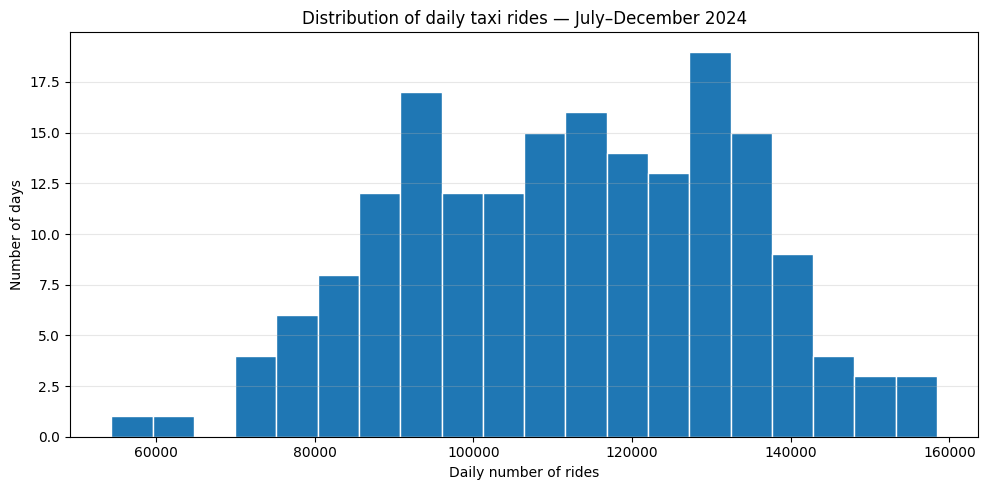

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(dataset["trip_count"].to_numpy(), bins=20, edgecolor="white")
ax.set_title("Distribution of daily taxi rides — July–December 2024")
ax.set_xlabel("Daily number of rides")
ax.set_ylabel("Number of days")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

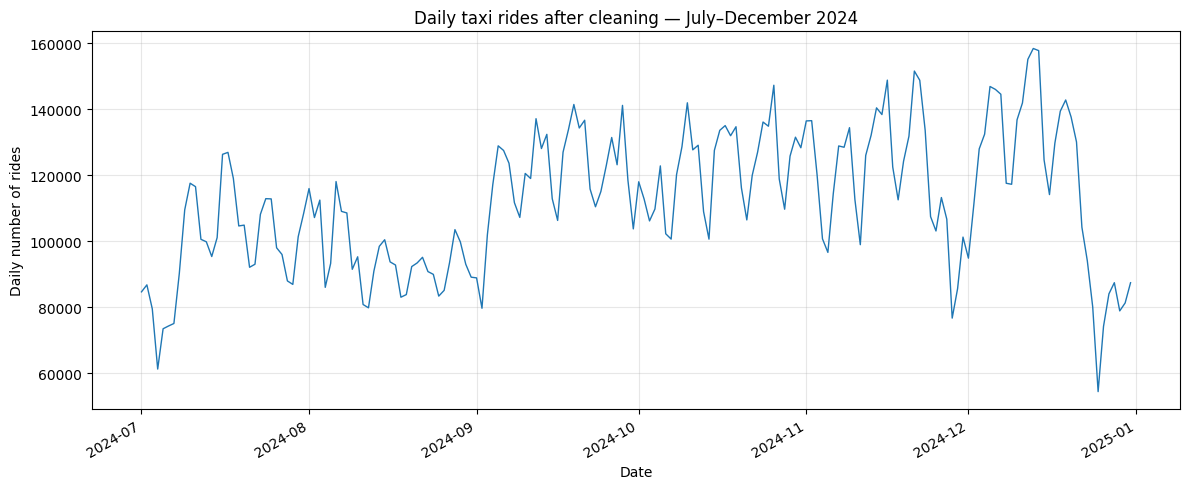

In [14]:
daily_target = dataset.sort("date")
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    daily_target["date"].to_list(), daily_target["trip_count"].to_list(), linewidth=1
)
ax.set_title("Daily taxi rides after cleaning — July–December 2024")
ax.set_xlabel("Date")
ax.set_ylabel("Daily number of rides")
ax.grid(alpha=0.3)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

### Observations

The final dataset contains **184 days and 36 columns**, covering 2024-07-01 to 2024-12-31. Each date occurs once, and the dataset has 0 missing values.

After cleaning, daily demand averages **112,141 rides**. The lowest count is **54,382** on 2024-12-25, and the highest is **158,430** on 2024-12-13. The histogram shows the distribution of daily counts; the sorted line plot preserves their chronological order and makes short-term fluctuations visible.

These results describe the selected July–December period and should not be treated as a full-year analysis. For future-demand forecasting, same-day aggregates such as total fares or payment counts would need to be lagged or otherwise known at prediction time to avoid target leakage.